# 5.2 How Neural Networks Learn from Images

**Module 5 · Note 2**

In Note 5.1 you saw that a network can learn its own description of an image, and that this learned description beat both raw pixels and features designed by hand. But the network we used there, a multilayer perceptron, has a hidden weakness: before it does anything, it **flattens** the image into one long list of numbers. In doing so it throws away the one thing that makes an image an image: which pixels sit next to which.

This note introduces the network designed to keep that information: the **convolutional neural network**, or **CNN**. CNNs were the architecture that made deep learning famous, and the ideas inside them (small reusable filters, feature maps, and building understanding layer by layer) appear again throughout modern AI, including in the vision models you will meet in Modules 6 and 7.

We will first see the whole system, then take it apart piece by piece, and finally train one on Fashion-MNIST and look inside it to see what it learned.

**Key question:** *How can a network take advantage of the fact that, in an image, position and neighbourhood matter?*

**By the end of this note you will be able to:**
- describe how images are stored as tensors, and work confidently with their shapes;
- explain, with evidence, why flattening an image loses information;
- explain what a convolutional filter does and compute one by hand;
- calculate the output shape of convolution and pooling layers;
- build, train and evaluate a CNN in PyTorch, and inspect what its layers learned.

**Before you start:** read Note 5.1 first. You should also be comfortable with the PyTorch training loop (`zero_grad`, forward pass, `loss.backward()`, `optimizer.step()`) and with tensor shapes.

### Setup

Run this cell first. It imports the libraries used in this note and fixes the random seeds so that your results match the numbers written here. `torch.nn.functional`, imported as `F`, gives us direct access to operations such as convolution and pooling without creating a layer object.

In [1]:
import os, gzip, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cpu


## 1. The Big Picture: From Pixels to Visual Understanding

Think about how you would describe the way *you* recognise a sneaker. You don't examine each point of the photo separately. You notice edges where the shoe meets the background, the curve of the sole, the stripes on the side, the laces. Those local details are found *wherever they appear* in the picture, and then combined into the overall shape that says "sneaker".

A CNN is built to work in the same spirit. It has three big ideas:

1. **Look locally.** Instead of connecting every pixel to every unit, a CNN slides a small window, typically 3×3 pixels, across the image and asks the same question at every position: "Is my pattern here?" The small window of weights is called a **filter** (or **kernel**).
2. **Reuse the same detector everywhere.** The filter's weights are the same at every position. A vertical-edge detector that works in the top-left corner also works in the bottom-right. This is called **weight sharing**.
3. **Build up in stages.** The output of one layer of filters, a set of **feature maps** showing where each pattern was found, becomes the input to the next layer. Early layers find simple patterns such as edges; later layers combine them into parts and shapes. Every so often, a **pooling** layer shrinks the maps so that later layers see a wider area.

At the end, a small fully connected **head**, exactly the kind of head you met in Note 5.1, turns the final feature maps into a prediction.

> 🖼 *IMAGE 5.2.1 — A CNN at a Glance.* A left-to-right pipeline diagram on a white background. Far left: a 28×28 greyscale sneaker image drawn as a flat square, labelled "input 1×28×28". Next: a stack of 16 thin, slightly offset translucent squares the same size, labelled "conv1 + ReLU → 16 feature maps (16×28×28)"; on the input image, a small highlighted 3×3 orange square with a dotted line to one pixel on the first feature map, labelled "one 3×3 filter, slid everywhere". Next: a smaller stack labelled "pool → 16×14×14". Next: a deeper stack of 32 smaller squares labelled "conv2 + ReLU → 32×14×14". Next: an even smaller stack labelled "pool → 32×7×7". Then a long thin vertical bar labelled "flatten → 1,568 numbers", then a small orange box labelled "head (fully connected)", then 10 thin output bars with the tallest labelled "Sneaker". Above the first half, a bracket labelled "ENCODER: finds patterns, keeps the 2D layout"; above the second half, a bracket labelled "HEAD: makes the decision". Takeaway: a CNN is an encoder made of local, shared filters followed by a small classifier.

Keep this picture in mind. Sections 2 and 3 explain the input and the problem CNNs solve; Sections 4 to 7 examine each part; Sections 8 and 9 put the whole thing to work.

## 2. Representing Images as Tensors

Before any network can process an image, the image has to be stored as a **tensor**: a multi-dimensional array of numbers, which you have used throughout the course. For images, the *shape* of that tensor follows a convention that you need to know well, because most bugs in vision code are shape bugs.

Let's load Fashion-MNIST again. This time we also download its separate **test set**: 10,000 images that we will touch only once, at the very end of the note.

In [2]:
DATA_DIR = "data/fashion"
BASE_URL = "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/"
FILES = {"train_x": "train-images-idx3-ubyte.gz", "train_y": "train-labels-idx1-ubyte.gz",
         "test_x": "t10k-images-idx3-ubyte.gz", "test_y": "t10k-labels-idx1-ubyte.gz"}
os.makedirs(DATA_DIR, exist_ok=True)
for f in FILES.values():
    path = os.path.join(DATA_DIR, f)
    if not os.path.exists(path):
        urllib.request.urlretrieve(BASE_URL + f, path)

def read_idx(name, offset):
    with gzip.open(os.path.join(DATA_DIR, FILES[name])) as fh:
        return np.frombuffer(fh.read(), dtype=np.uint8, offset=offset)

train_images = read_idx("train_x", 16).reshape(-1, 28, 28)
train_labels = read_idx("train_y", 8)
test_images  = read_idx("test_x", 16).reshape(-1, 28, 28)
test_labels  = read_idx("test_y", 8)
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("train:", train_images.shape, "| test:", test_images.shape)

train: (60000, 28, 28) | test: (10000, 28, 28)


The raw arrays have shape `(60000, 28, 28)` and `(10000, 28, 28)`: number of images, height, width. PyTorch's convolution layers expect one more dimension, the number of **channels**. A channel is one "layer" of values per pixel. A greyscale image has 1 channel (brightness). A colour image has 3 channels (red, green and blue), so every pixel is described by three numbers.

PyTorch's standard layout for a batch of images is therefore:

$$(N,\ C,\ H,\ W) = (\text{batch size},\ \text{channels},\ \text{height},\ \text{width})$$

The cell below adds the channel dimension with `unsqueeze(1)`, scales the values from 0–255 to 0–1, and splits the 60,000 training images into 50,000 for training and 10,000 for validation.

In [3]:
# convert to float tensors in [0, 1] and add a channel dimension: (N, 28, 28) -> (N, 1, 28, 28)
X_all = torch.tensor(train_images, dtype=torch.float32).unsqueeze(1) / 255.0
y_all = torch.tensor(train_labels, dtype=torch.long)
X_test = torch.tensor(test_images, dtype=torch.float32).unsqueeze(1) / 255.0
y_test = torch.tensor(test_labels, dtype=torch.long)

X_train, y_train = X_all[:50000], y_all[:50000]
X_val,   y_val   = X_all[50000:], y_all[50000:]
print("one image:", X_train[0].shape)
print("training set:", X_train.shape, "| validation:", X_val.shape, "| test:", X_test.shape)
print("dtype:", X_train.dtype, "| min:", X_train.min().item(), "| max:", X_train.max().item())

one image: torch.Size([1, 28, 28])
training set: torch.Size([50000, 1, 28, 28]) | validation: torch.Size([10000, 1, 28, 28]) | test: torch.Size([10000, 1, 28, 28])
dtype: torch.float32 | min: 0.0 | max: 1.0


A single image is now `[1, 28, 28]`: 1 channel, 28 rows, 28 columns. The training set is `[50000, 1, 28, 28]`. Values run from 0.0 to 1.0, stored as 32-bit floats, which is what PyTorch layers expect.

During training we feed the network **batches** (small groups of images processed together), so a batch of 64 images has shape `[64, 1, 28, 28]`. A colour image of 32×32 pixels would be `[3, 32, 32]`.

In [4]:
batch = X_train[:64]
print("a batch of 64:", batch.shape)
rgb = torch.zeros(3, 32, 32)
print("an RGB image (channels, height, width):", rgb.shape)
print("what matplotlib wants for RGB (height, width, channels):", rgb.permute(1, 2, 0).shape)

a batch of 64: torch.Size([64, 1, 28, 28])
an RGB image (channels, height, width): torch.Size([3, 32, 32])
what matplotlib wants for RGB (height, width, channels): torch.Size([32, 32, 3])


Notice the last line. PyTorch puts channels **first** (`C, H, W`), but most image libraries, including matplotlib, put channels **last** (`H, W, C`). `permute(1, 2, 0)` reorders the dimensions, turning `[3, 32, 32]` into `[32, 32, 3]`.

> **Common mistake:** passing a `[3, H, W]` tensor straight to `plt.imshow`, or passing an `[H, W, 3]` image straight into a PyTorch convolution. The first gives an error or a garbled picture; the second makes PyTorch treat the image's *height* as if it were the number of channels. Whenever an image looks wrong or a layer complains about channels, print `.shape` first.

> **Key terms**
> - **Channel:** one value per pixel of a particular kind, such as brightness, or the red, green or blue component. Greyscale images have 1 channel; colour images have 3.
> - **Channels-first / channels-last:** the order of dimensions. PyTorch uses `(N, C, H, W)`; matplotlib and many image libraries use `(H, W, C)`.
> - **Batch:** a group of examples processed together; it adds a leading dimension `N`.

> **Check yourself 1.** A batch of 16 colour photos, each 224 pixels tall and 224 pixels wide, is stored for PyTorch. What is its shape?

## 3. Why Flattening Images Loses Spatial Structure

The MLP from Note 5.1 begins with `nn.Flatten()`, which turns each `[1, 28, 28]` image into a list of 784 numbers. That seems harmless. Let's see what it does to neighbouring pixels.

In [5]:
def flat_index(row, col, width=28):
    return row * width + col

for (r, c) in [(10, 10), (10, 11), (11, 10)]:
    print(f"pixel at row {r}, col {c} -> position {flat_index(r, c)} in the flattened vector")
print("values per image after flattening:", 28 * 28)

pixel at row 10, col 10 -> position 290 in the flattened vector
pixel at row 10, col 11 -> position 291 in the flattened vector
pixel at row 11, col 10 -> position 318 in the flattened vector
values per image after flattening: 784


The pixel at row 10, column 10 ends up at position 290. Its right-hand neighbour lands next to it at 291. But its neighbour directly **below**, which is just as close in the picture, lands at position 318, 28 places away. After flattening, the MLP receives a list of 784 numbers with no record of which ones were neighbours. Any notion of "above", "below" or "nearby" is gone, and the network would have to rediscover it from data.

There is a neat experiment that proves this. Choose one random rearrangement (a **permutation**) of the 784 pixel positions, and apply that *same* rearrangement to every image. To a human, the result is noise:

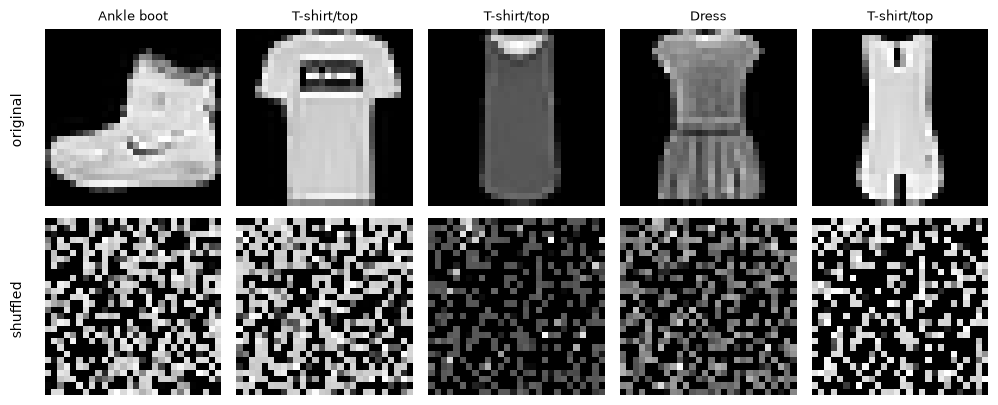

In [6]:
perm = torch.randperm(784, generator=torch.Generator().manual_seed(1))
def shuffle_pixels(X):
    return X.flatten(1)[:, perm].reshape(-1, 1, 28, 28)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.2))
for j in range(5):
    axes[0, j].imshow(X_train[j, 0], cmap="gray"); axes[0, j].set_title(CLASSES[y_train[j]], fontsize=9)
    axes[1, j].imshow(shuffle_pixels(X_train[j:j+1])[0, 0], cmap="gray")
for ax in axes.flat: ax.axis("off")
axes[0, 0].text(-6, 14, "original", rotation=90, va="center", fontsize=10)
axes[1, 0].text(-6, 14, "shuffled", rotation=90, va="center", fontsize=10)
plt.tight_layout(); plt.show()

The shuffled images are unrecognisable to us. But nothing has been lost from the MLP's point of view. Every image still contains exactly the same 784 values, just in a consistently different order, and the MLP never knew the order meant anything.

To test this, we need a model and a training loop. The MLP below is the same shape as in Note 5.1. We also write two helper functions that we will reuse throughout this note:

- `evaluate` returns the accuracy and the predictions. It switches the model to evaluation mode with `model.eval()` and turns off gradient tracking, then switches back.
- `train` is the familiar training loop, with an optional list `snapshots` that stores a copy of the weights after every epoch, so that we can later pick the best epoch.

In [7]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 10))
    def forward(self, x):
        return self.net(x)

In [8]:
def evaluate(model, X, y, bs=1000):
    model.eval()
    preds = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            preds.append(model(X[i:i+bs]).argmax(1))
    model.train()
    preds = torch.cat(preds)
    return (preds == y).float().mean().item(), preds

def train(model, X, y, Xv, yv, epochs, lr=1e-3, bs=128, seed=0, verbose=True, snapshots=None):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    history = []
    for epoch in range(epochs):
        perm_ = torch.randperm(len(X))
        total, n = 0.0, 0
        for i in range(0, len(X), bs):
            b = perm_[i:i+bs]
            opt.zero_grad()
            loss = loss_fn(model(X[b]), y[b])
            loss.backward()
            opt.step()
            total += loss.item(); n += 1
        val_acc, _ = evaluate(model, Xv, yv)
        history.append((total / n, val_acc))
        if snapshots is not None:
            snapshots.append({k: v.clone() for k, v in model.state_dict().items()})
        if verbose:
            print(f"  epoch {epoch+1}: train loss {total/n:.3f} | val acc {val_acc:.4f}")
    return history

Now we train two identical MLPs, with the same starting weights, for 2 epochs each: one on the original images, one on the shuffled images.

In [9]:
Xs_train, Xs_val = shuffle_pixels(X_train), shuffle_pixels(X_val)
mlp_preds = {}
for data_name, (Xt, Xv) in [("original", (X_train, X_val)), ("shuffled", (Xs_train, Xs_val))]:
    torch.manual_seed(0)
    mlp = MLP()
    train(mlp, Xt, y_train, Xv, y_val, epochs=2, verbose=False)
    acc, mlp_preds[data_name] = evaluate(mlp, Xv, y_val)
    print(f"MLP on {data_name:<8} pixels: val acc {acc:.4f}")

MLP on original pixels: val acc 0.8528


MLP on shuffled pixels: val acc 0.8527


The two accuracies are 0.8528 and 0.8527, essentially identical. But are they *really* the same, or is a small difference hiding behind the rounding? With a validation set of 10,000 images, one image is worth 0.0001 of accuracy, so the two models differ by a single image overall.

A more careful check is the **sign test**. We ignore the images that both models get right or both get wrong (they tell us nothing about which model is better) and count the disagreements. If the two models were truly equally good, each disagreement would be a coin flip.

In [10]:
from scipy.stats import binomtest
def sign_test(pred_a, pred_b, y):
    a_right_b_wrong = ((pred_a == y) & (pred_b != y)).sum().item()
    b_right_a_wrong = ((pred_b == y) & (pred_a != y)).sum().item()
    p = binomtest(a_right_b_wrong, a_right_b_wrong + b_right_a_wrong).pvalue
    return a_right_b_wrong, b_right_a_wrong, p

a, b, p = sign_test(mlp_preds["original"], mlp_preds["shuffled"], y_val)
print(f"right only on original: {a} | right only on shuffled: {b} | sign-test p = {p:.3g}")
print("one validation image is worth", 1 / len(y_val), "of accuracy")

right only on original: 90 | right only on shuffled: 89 | sign-test p = 1
one validation image is worth 0.0001 of accuracy


Here the original-pixel MLP was right on 90 images that the shuffled one got wrong, and the shuffled one was right on 89 that the original got wrong. The p-value of 1 says this split is exactly what a fair coin would produce: no evidence of any difference.

So the MLP **completely ignores the spatial arrangement of pixels**. That is a weakness: it means the MLP cannot use the most basic fact about images, that nearby pixels belong together. A model that *did* use that fact should do better on real images, and worse on shuffled ones. We will test exactly that in Section 8.

> **Key terms**
> - **Spatial structure:** the arrangement of pixels in two dimensions: which pixels are neighbours.
> - **Permutation:** a rearrangement of positions. Here, the same random reordering of the 784 pixels was applied to every image.
> - **Sign test:** a test that compares two models by counting only the examples where they disagree, and asks whether the split could be due to chance. We use `scipy.stats.binomtest`.

> **Check yourself 2.** Why did we apply the *same* permutation to every image, instead of a different random shuffle for each one?

## 4. Convolutional Neural Networks: The Complete Picture

We have seen the problem: an MLP treats an image as an unordered list. Here is the full CNN we will use in this note, before we examine its pieces. Read the comments on the right: they show the shape of the data after each layer, for a batch of `N` images.

In [11]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),   # (N, 1, 28, 28) -> (N, 16, 28, 28)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> (N, 16, 14, 14)
            nn.Conv2d(16, 32, kernel_size=3, padding=1),  # -> (N, 32, 14, 14)
            nn.ReLU(),
            nn.MaxPool2d(2),                              # -> (N, 32, 7, 7)
        )
        self.head = nn.Sequential(
            nn.Flatten(),                                 # -> (N, 1568)
            nn.Linear(32 * 7 * 7, 64), nn.ReLU(),         # -> (N, 64)
            nn.Linear(64, 10),                            # -> (N, 10)
        )
    def forward(self, x):
        return self.head(self.features(x))

count = lambda m: sum(p.numel() for p in m.parameters())
print("MLP parameters:", count(MLP()))
print("CNN parameters:", count(SmallCNN()))

MLP parameters: 101770
CNN parameters: 105866


The two networks are almost the same size: 101,770 parameters for the MLP and 105,866 for the CNN. So any difference in how they behave is about *how* the parameters are arranged, not how many there are.

The CNN is organised exactly as the encoder–head split from Note 5.1:

- **`features` (the encoder)** contains two rounds of *convolution → ReLU → pooling*. Throughout this part, the data stays in the 2D shape `(channels, height, width)`, so spatial structure is preserved.
- **`head`** flattens the final feature maps and classifies them with two fully connected layers. By this point, the encoder has already turned "where is everything" into "which patterns are present", so flattening no longer throws away anything important.

The best way to understand a network's shapes is to watch data flow through it. The cell below passes a dummy batch of 8 images through each layer and prints the shape after every step.

In [12]:
model = SmallCNN()
x = torch.zeros(8, 1, 28, 28)                 # a dummy batch of 8 images
print(f"{'input':<10} {tuple(x.shape)}")
for layer in list(model.features) + list(model.head):
    x = layer(x)
    print(f"{layer.__class__.__name__:<10} {tuple(x.shape)}")

input      (8, 1, 28, 28)
Conv2d     (8, 16, 28, 28)
ReLU       (8, 16, 28, 28)
MaxPool2d  (8, 16, 14, 14)
Conv2d     (8, 32, 14, 14)
ReLU       (8, 32, 14, 14)
MaxPool2d  (8, 32, 7, 7)
Flatten    (8, 1568)
Linear     (8, 64)
ReLU       (8, 64)
Linear     (8, 10)


Follow the numbers down the list:

- **Conv2d (first):** 1 channel in, 16 out. The image stays 28×28, but we now have 16 feature maps per image, one for each filter.
- **MaxPool2d:** height and width halve to 14×14; the number of channels does not change.
- **Conv2d (second):** 16 channels in, 32 out, still 14×14.
- **MaxPool2d:** down to 7×7.
- **Flatten:** 32 × 7 × 7 = 1,568 numbers per image.
- **Linear layers:** 1,568 → 64 → 10 class scores.

Notice the trade the encoder makes as data flows through it: the maps get **smaller** (28 → 14 → 7) while the number of channels gets **larger** (1 → 16 → 32). The network gives up fine positional detail in exchange for a richer description of *what* is present.

Every piece in this list is examined in the next three sections: the filters and feature maps produced by `Conv2d` (Section 5), the size changes caused by padding and pooling (Section 6), and why stacking layers builds hierarchical features (Section 7).

> **Check yourself 3.** If we removed the second `MaxPool2d`, what would the shape after `Flatten` become?

## 5. Convolutional Filters and Feature Maps

The central operation of a CNN is **convolution**. The idea is simple: take a small grid of weights, the filter, place it over a patch of the image, multiply each weight by the pixel underneath it, and add everything up. That sum is one output value. Then slide the filter one step and repeat, until you have covered the whole image. The grid of outputs is a **feature map**.

### 5.1 A convolution you can check by hand

Let's do this on a tiny 5×5 image, so that every number is visible. The image is dark (0) in its two left columns and bright (1) in its three right columns, so it contains one vertical edge. Our filter has −1 in its left column, 0 in the middle and +1 on the right. In words, the filter asks: *"Is it brighter on my right than on my left?"*

In [13]:
x = torch.zeros(5, 5)
x[:, 2:] = 1.0                       # dark on the left, bright on the right: a vertical edge
k = torch.tensor([[-1., 0., 1.],
                  [-1., 0., 1.],
                  [-1., 0., 1.]])    # responds to "brighter on the right than on the left"
print("input:\n", x)
out = torch.zeros(3, 3)
for i in range(3):
    for j in range(3):
        patch = x[i:i+3, j:j+3]
        out[i, j] = (patch * k).sum()
print("by hand:\n", out)
print("F.conv2d:\n", F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))[0, 0])

input:
 tensor([[0., 0., 1., 1., 1.],
        [0., 0., 1., 1., 1.],
        [0., 0., 1., 1., 1.],
        [0., 0., 1., 1., 1.],
        [0., 0., 1., 1., 1.]])
by hand:
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])
F.conv2d:
 tensor([[3., 3., 0.],
        [3., 3., 0.],
        [3., 3., 0.]])


Take the top-left output value. The filter covers rows 0–2 and columns 0–2 of the input. The left column of that patch is 0, 0, 0 (multiplied by −1 gives 0); the middle column is 0, 0, 0 (multiplied by 0 gives 0); the right column is 1, 1, 1 (multiplied by +1 gives 3). The total is 3. The filter has found an edge.

Now take the top-right output value. The patch covers columns 2–4, which are all bright. The left column gives −3, the right column gives +3, and they cancel to 0. No edge there, so no response. Our hand calculation and PyTorch's `F.conv2d` agree exactly.

Two facts about this output are worth noticing:

- **The 5×5 input produced a 3×3 output.** A 3×3 filter only fits in 3 positions across a 5-wide image. We'll return to this in Section 6.
- **The filter's weights add up to zero.** So on a perfectly uniform patch, whether all dark or all bright, it outputs 0. It responds only to *change*. That is what makes it an edge detector.

> **A note on the name:** strictly, what deep-learning libraries compute is called *cross-correlation*; mathematical convolution also flips the filter first. Because the filter's weights are learned anyway, the flip makes no practical difference, and everyone in deep learning simply calls it convolution.

### 5.2 Filters on a real image

Now apply two classic hand-designed edge filters to the ankle boot. The first is a stronger version of the vertical-edge filter above; the second is the same filter turned on its side, which detects horizontal edges. Notice that we stack the two filters into one tensor of shape `[2, 1, 3, 3]` (2 filters, each looking at 1 input channel, each 3×3), and `F.conv2d` produces one feature map per filter.

filter bank shape: torch.Size([2, 1, 3, 3])
feature maps shape: torch.Size([1, 2, 28, 28])


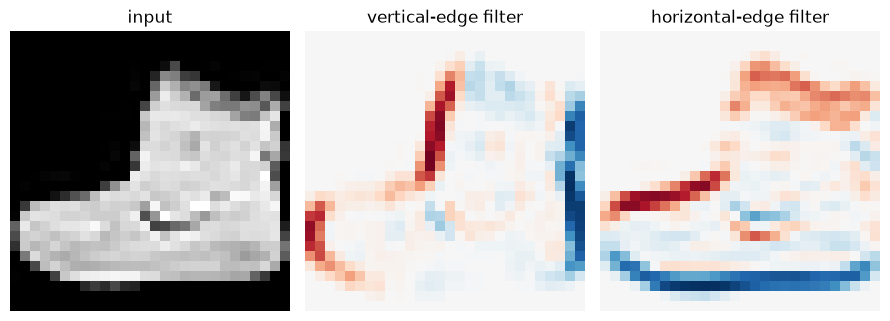

In [14]:
boot = X_train[0:1]                  # shape (1, 1, 28, 28)
vertical   = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])
horizontal = vertical.T.contiguous()
filters = torch.stack([vertical, horizontal]).unsqueeze(1)   # (2 filters, 1 channel, 3, 3)
print("filter bank shape:", filters.shape)
maps = F.conv2d(boot, filters, padding=1)                     # (1, 2, 28, 28)
print("feature maps shape:", maps.shape)
fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
axes[0].imshow(boot[0, 0], cmap="gray"); axes[0].set_title("input")
for j, t in enumerate(["vertical-edge filter", "horizontal-edge filter"]):
    m = maps[0, j].abs().max()
    axes[j+1].imshow(maps[0, j], cmap="RdBu_r", vmin=-m, vmax=m); axes[j+1].set_title(t)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

Each feature map is a picture of *where the filter's pattern occurs*. In the vertical-edge map, the left side of the boot is red (dark on the left, bright on the right) and its right side is blue (bright on the left, dark on the right). In the horizontal-edge map, the top edges and the sole light up instead. One filter, slid across the whole image, has produced a full map of one kind of feature.

In a CNN, nobody designs these filters by hand. The first `Conv2d` layer of our network has 16 filters whose weights start random and are **learned** by backpropagation, just like the weights of any other layer. The network discovers which patterns are worth detecting. We will look at what it learns in Section 9.

### 5.3 Why sharing one filter everywhere is so efficient

Because each filter is reused at every position, a convolution layer needs remarkably few parameters. Compare our first convolution layer with a fully connected layer that produces the same number of outputs:

In [15]:
conv = nn.Conv2d(1, 16, kernel_size=3, padding=1)
outputs = 16 * 28 * 28
dense_params = 784 * outputs + outputs
print("conv layer parameters:", count(conv), "| outputs it produces:", outputs)
print("a fully connected layer with the same inputs and outputs would need:", f"{dense_params:,}")
print("ratio:", f"{dense_params / count(conv):,.0f}x")

conv layer parameters: 160 | outputs it produces: 12544
a fully connected layer with the same inputs and outputs would need: 9,847,040
ratio: 61,544x


Our first convolution layer has 160 parameters: 16 filters × 9 weights, plus 16 biases. It produces 12,544 output values (16 maps of 28×28). A fully connected layer mapping the same 784 inputs to the same 12,544 outputs would need 9,847,040 parameters, 61,544 times as many.

That saving comes from two assumptions built into convolution:

- **Locality:** each output depends only on a small neighbourhood of the input, because nearby pixels matter most.
- **Weight sharing:** the same pattern is worth detecting anywhere in the image.

Assumptions like these are called an **inductive bias**: knowledge about the problem that is built into the architecture rather than learned from data. When the assumptions are true, as they are for images, the network learns faster from less data. When they are false, they can hurt. You will see both outcomes in Section 8.

> **Key terms**
> - **Filter (kernel):** a small grid of learnable weights that is slid across the input.
> - **Convolution:** sliding a filter over the input and, at each position, computing the sum of weights × inputs.
> - **Feature map:** the grid of outputs a filter produces; it shows where the filter's pattern appears.
> - **Weight sharing:** using the same filter weights at every position.
> - **Inductive bias:** an assumption about the problem built into a model's design.

> **Check yourself 4.** A filter has the weights `[[1, 1, 1], [1, 1, 1], [1, 1, 1]]`. What does its feature map show, and would it be a good edge detector?

## 6. Stride, Padding, and Pooling

In Section 5.1 a 3×3 filter shrank a 5×5 image to 3×3. If every layer shrank the image like that, a deep network would quickly run out of image, and the pixels near the border would be used less than those in the middle. Three settings control what happens to the size of the data: **padding**, **stride** and **pooling**.

### 6.1 Padding and stride

- **Padding** adds a border of zeros around the input before the filter is applied. With a 3×3 filter, adding one pixel of padding on every side (`padding=1`) keeps the output the same size as the input. That is why our CNN's convolutions keep 28×28 as 28×28.
- **Stride** is how far the filter moves at each step. With `stride=1` it visits every position; with `stride=2` it skips every other position, roughly halving the output size.

These combine into one formula for the output size along each dimension:

$$\text{output size} = \left\lfloor \frac{\text{input size} + 2 \times \text{padding} - \text{kernel size}}{\text{stride}} \right\rfloor + 1$$

The brackets ⌊ ⌋ mean "round down to a whole number". Let's check the formula against PyTorch for several settings on a 28×28 input:

In [16]:
def conv_out(size, kernel, stride=1, padding=0):
    return (size + 2 * padding - kernel) // stride + 1

configs = [(3, 1, 0), (3, 1, 1), (3, 2, 1), (5, 1, 2), (5, 2, 0)]
for kernel, stride, padding in configs:
    layer = nn.Conv2d(1, 4, kernel_size=kernel, stride=stride, padding=padding)
    actual = layer(torch.zeros(1, 1, 28, 28)).shape[-1]
    print(f"kernel={kernel} stride={stride} padding={padding}: formula {conv_out(28, kernel, stride, padding)}, PyTorch {actual}")

kernel=3 stride=1 padding=0: formula 26, PyTorch 26
kernel=3 stride=1 padding=1: formula 28, PyTorch 28
kernel=3 stride=2 padding=1: formula 14, PyTorch 14
kernel=5 stride=1 padding=2: formula 28, PyTorch 28
kernel=5 stride=2 padding=0: formula 12, PyTorch 12


The formula and PyTorch agree in every case. Take the first line: (28 + 0 − 3) / 1 + 1 = 26. Without padding, a 3×3 filter loses one pixel on each side. Add `padding=1` and the result is 28 again. With `stride=2` as well, the output drops to 14.

> **Common mistake:** getting the input size of the first `nn.Linear` after `Flatten` wrong. It must equal channels × height × width of the last feature maps (here 32 × 7 × 7). If you change any padding, stride or pooling setting, recompute it with the formula, or simply pass a dummy batch through the encoder and print the shape, as we did in Section 4.

### 6.2 Pooling

**Pooling** shrinks a feature map by summarising small blocks of it. A 2×2 pool with stride 2 splits the map into non-overlapping 2×2 blocks and replaces each block by one number:

- **Max pooling** keeps the largest value: "was the pattern found *anywhere* in this block?"
- **Average pooling** keeps the mean value: "how strongly, on average, was it found here?"

Here is a 4×4 grid pooled both ways:

In [17]:
grid = torch.tensor([[1., 3., 2., 0.],
                     [4., 6., 1., 1.],
                     [0., 2., 9., 5.],
                     [1., 1., 3., 7.]]).view(1, 1, 4, 4)
print("max pool 2x2:\n", F.max_pool2d(grid, 2)[0, 0])
print("average pool 2x2:\n", F.avg_pool2d(grid, 2)[0, 0])

max pool 2x2:
 tensor([[6., 2.],
        [2., 9.]])
average pool 2x2:
 tensor([[3.5000, 1.0000],
        [1.0000, 6.0000]])


The top-left block contains 1, 3, 4 and 6. Max pooling keeps 6; average pooling gives (1 + 3 + 4 + 6) / 4 = 3.5. The bottom-right block contains 9, 5, 3 and 7, which gives 9 and 6.

Max pooling is the usual choice inside CNNs because of what it throws away. If an edge shifts by one pixel within a block, the maximum hardly changes. So the network becomes a little less sensitive to exactly *where* a pattern appears, which is usually what we want for recognising objects. Pooling also has no learnable parameters at all.

> **Key terms**
> - **Padding:** extra values (usually zeros) added around the input's border.
> - **Stride:** the step size of the filter as it slides.
> - **Pooling:** summarising small blocks of a feature map (by max or average) to make it smaller.

> **Check yourself 5.** Use the formula to find the output size of a convolution with kernel size 7, stride 2 and padding 3, applied to a 224×224 image.

## 7. Hierarchical Feature Learning: From Edges to Objects

A single 3×3 filter can only see 3×3 pixels. That is enough for an edge, but not for a sole, let alone a whole boot. So how does a CNN ever recognise large shapes?

The answer is stacking. The second convolution layer does not look at pixels; it looks at the *feature maps* from the first layer. Each of its outputs covers a 3×3 block of those maps, and each of *those* values already summarised a 3×3 block of pixels. Pooling in between makes the reach grow faster still. The region of the original image that can influence one output value is called its **receptive field**.

We can measure the receptive field directly. We pass an image through the encoder, pick the output value at the centre of the final map, and use backpropagation to ask: *which input pixels have any effect on it?* Pixels whose gradient is not zero are inside the receptive field. (For this measurement we use average pooling instead of max pooling, because max pooling passes the gradient only to the single winning pixel in each block, which would hide part of the window. The receptive field is the same size either way.) We also compute the same quantity with a simple formula: each layer adds (kernel size − 1) × (the combined stride of all earlier layers).

In [18]:
def receptive_field(layers):
    x = torch.zeros(1, 1, 28, 28, requires_grad=True)
    out = layers(x)
    c = out.shape[-1] // 2
    out[0, 0, c, c].backward()               # which input pixels affect the centre output?
    return (x.grad[0, 0].abs().sum(1) > 0).sum().item()

# Same layer sizes as SmallCNN, but average pooling, so the gradient reaches every pixel in each window
probe = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.AvgPool2d(2),
                      nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.AvgPool2d(2))
for p in probe.parameters():
    nn.init.constant_(p, 0.1)                 # positive weights so every path is "on"

r, jump = 1, 1                                # the same calculation by formula
for name, end, k, s_ in [("after conv1", 2, 3, 1), ("after pool1", 3, 2, 2),
                         ("after conv2", 5, 3, 1), ("after pool2", 6, 2, 2)]:
    r, jump = r + (k - 1) * jump, jump * s_
    print(f"{name:<12} measured {receptive_field(probe[:end])}x{receptive_field(probe[:end])} | formula {r}x{r}")

after conv1  measured 3x3 | formula 3x3
after pool1  measured 4x4 | formula 4x4
after conv2  measured 8x8 | formula 8x8
after pool2  measured 10x10 | formula 10x10


Measured and calculated agree: the receptive field grows from 3×3 after the first convolution, to 4×4 after the first pool, to 8×8 after the second convolution, and to 10×10 after the second pool. In a 28×28 image, a 10×10 window is large enough to cover a whole heel, a strap or the toe of a shoe.

This growth is the mechanism behind **hierarchical feature learning**:

- **First layer, small receptive field:** can only detect simple local patterns, such as edges, spots and changes of brightness.
- **Second layer, larger receptive field:** combines several edge maps, so it can detect corners, curves and textures: the *parts* of an object.
- **Deeper layers in larger networks:** keep combining, so later units can respond to whole objects. The networks that classify ordinary photos have dozens of layers and receptive fields covering most of the image.

> 🖼 *IMAGE 5.2.2 — Growing Receptive Fields.* Three stacked square grids drawn in perspective, bottom to top, on a white background. Bottom grid: a 12×12 pixel grid labelled "input image", with a faint sneaker outline drawn across it. Middle grid: a smaller grid labelled "layer 1 feature map". Top grid: a still smaller grid labelled "layer 2 feature map". One single highlighted cell on the top grid (orange) has lines fanning down to a 3×3 orange block on the middle grid, and from the edges of that block, lines fan further down to a larger highlighted block on the input grid (light orange, about 8×8 cells), which covers the toe of the sneaker. Labels on the side: "3×3 window", "covers 8×8 pixels". Takeaway: each layer looks at a small window of the layer below, so deeper units see more of the image.

> **Key terms**
> - **Receptive field:** the region of the input image that can affect one particular output value.
> - **Hierarchical features:** features organised in levels, with each level combining the simpler features of the level below.

> **Check yourself 6.** Our network's receptive field after the second pool is 10×10, yet the network classifies whole 28×28 garments. How can the head still use information from the whole image?

## 8. CNNs in Practice with PyTorch

We have now seen every part of the CNN. Let's train the whole thing and test whether its built-in assumptions pay off.

### 8.1 Training and choosing the epoch on validation

We train for 5 epochs with the Adam optimizer and a learning rate of 0.001, using the `train` function from Section 3. After each epoch we record the training loss and the validation accuracy, and keep a snapshot of the weights. At the end, we pick the epoch with the best **validation** accuracy. We never use the test set to make this choice; it stays untouched until the final evaluation.

In [19]:
torch.manual_seed(0)
cnn = SmallCNN()
snaps = []
history = train(cnn, X_train, y_train, X_val, y_val, epochs=5, snapshots=snaps)
best_epoch = int(np.argmax([h[1] for h in history])) + 1
print("best epoch on validation:", best_epoch)
_ = cnn.load_state_dict(snaps[best_epoch - 1])   # keep the best epoch's weights

  epoch 1: train loss 0.678 | val acc 0.8392


  epoch 2: train loss 0.392 | val acc 0.8643


  epoch 3: train loss 0.337 | val acc 0.8803


  epoch 4: train loss 0.305 | val acc 0.8889


  epoch 5: train loss 0.283 | val acc 0.8929
best epoch on validation: 5


The training loss falls every epoch, from 0.678 to 0.283, and validation accuracy rises every epoch, from 0.8392 to 0.8929. The best epoch on validation is therefore the last one, epoch 5, and those are the weights we keep. The plot shows both curves.

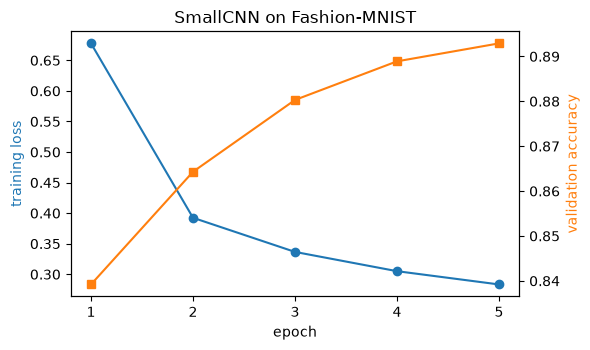

In [20]:
epochs = range(1, len(history) + 1)
fig, ax1 = plt.subplots(figsize=(6, 3.6))
ax1.plot(epochs, [h[0] for h in history], "o-", color="tab:blue", label="training loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(epochs, [h[1] for h in history], "s-", color="tab:orange", label="validation accuracy")
ax2.set_ylabel("validation accuracy", color="tab:orange")
ax1.set_xticks(list(epochs)); plt.title("SmallCNN on Fashion-MNIST"); fig.tight_layout(); plt.show()

Validation accuracy is still rising at epoch 5, so we have not trained to the point of overfitting; a few more epochs would probably help a little. We stop here to keep the notebook quick to run.

### 8.2 Does the CNN really use spatial structure?

In Section 3, the MLP did just as well on shuffled pixels as on real ones. If the CNN truly relies on neighbourhoods, it should **lose** accuracy when the pixels are shuffled, because its filters will be looking at "neighbours" that are not really neighbours.

To keep the comparison fair, we train a fresh CNN on shuffled images for 2 epochs, with the same starting weights, and compare it with our main CNN's snapshot after the same 2 epochs.

In [21]:
torch.manual_seed(0)
cnn_shuffled = SmallCNN()
train(cnn_shuffled, Xs_train, y_train, Xs_val, y_val, epochs=2, verbose=False)
cnn_epoch2 = SmallCNN(); _ = cnn_epoch2.load_state_dict(snaps[1])     # the main CNN after the same 2 epochs
acc_o, p_o = evaluate(cnn_epoch2, X_val, y_val)
acc_s, p_s = evaluate(cnn_shuffled, Xs_val, y_val)
print(f"CNN after 2 epochs, original pixels: {acc_o:.4f}")
print(f"CNN after 2 epochs, shuffled pixels: {acc_s:.4f}")
a, b, p = sign_test(p_o, p_s, y_val)
print(f"right only on original: {a} | right only on shuffled: {b} | sign-test p = {p:.3g}")

CNN after 2 epochs, original pixels: 0.8643
CNN after 2 epochs, shuffled pixels: 0.8341
right only on original: 557 | right only on shuffled: 255 | sign-test p = 1.14e-26


This time the difference is large. After 2 epochs, the CNN reaches 0.8643 on real images but only 0.8341 on shuffled ones. The sign test confirms it is not chance: the real-image CNN was right on 557 images that the shuffled one got wrong, against only 255 the other way round, with a p-value of 1.14e-26. A split that lopsided essentially never happens by luck.

Notice also that the CNN on shuffled pixels (0.8341) did *worse* than the MLP on shuffled pixels (0.8527). When the CNN's built-in assumption, that neighbouring pixels belong together, is false, it becomes a handicap. This is the inductive bias from Section 5.3 in action. It helps when it matches reality and hurts when it does not.

### 8.3 Final evaluation on the test set

Now, once and only once, we evaluate the chosen model on the 10,000 test images.

In [22]:
test_acc, test_preds = evaluate(cnn, X_test, y_test)
print(f"test accuracy (epoch {best_epoch} model): {test_acc:.4f}")
print(f"errors: {(test_preds != y_test).sum().item()} of {len(y_test)}")
for c in range(10):
    mask = y_test == c
    print(f"  {CLASSES[c]:<12} {(test_preds[mask] == c).float().mean().item():.3f}")

test accuracy (epoch 5 model): 0.8903
errors: 1097 of 10000
  T-shirt/top  0.845
  Trouser      0.959
  Pullover     0.767
  Dress        0.902
  Coat         0.888
  Sandal       0.959
  Shirt        0.694
  Sneaker      0.964
  Bag          0.970
  Ankle boot   0.955


The test accuracy is **0.8903**, very close to the final validation accuracy of 0.8929. That closeness is reassuring: it suggests we did not accidentally tune our choices to the validation set. Out of 10,000 test images, 1,097 are misclassified.

The per-class accuracies are far from equal. Bags (0.970), sneakers (0.964), trousers and sandals (0.959 each) are easy. Shirts (0.694) and pullovers (0.767) are hard. To see why, let's find the most common mistakes.

In [23]:
conf = torch.zeros(10, 10, dtype=torch.long)
for t, p_ in zip(y_test, test_preds):
    conf[t, p_] += 1
pairs = [(conf[i, j].item(), CLASSES[i], CLASSES[j]) for i in range(10) for j in range(10) if i != j]
for n, true, pred in sorted(pairs, reverse=True)[:4]:
    print(f"{n:>4} test images of '{true}' predicted as '{pred}'")

 121 test images of 'Pullover' predicted as 'Coat'
 119 test images of 'Shirt' predicted as 'T-shirt/top'
 105 test images of 'T-shirt/top' predicted as 'Shirt'
 105 test images of 'Shirt' predicted as 'Coat'


The four most common mistakes are all between upper-body garments: 121 pullovers predicted as coats, 119 shirts predicted as T-shirts, and 105 each of T-shirts predicted as shirts and shirts predicted as coats. At 28×28 greyscale, these items have nearly the same outline, and the details that separate them (buttons, collars, fabric texture) occupy only a few pixels. These are mistakes that a person squinting at the same tiny images would also make.

> **Common mistake:** reporting only the overall accuracy. An accuracy of 0.8903 hides the fact that the model is right on only 0.694 of shirts. Always look at per-class results and the most common confusions; they tell you where the model needs to improve and whether its errors are acceptable for your application.

> **Check yourself 7.** Why did we pick the best epoch using the validation set rather than the test set, given that the test set is also data the model never trained on?

## 9. Visualising Learned Filters and Feature Maps

In Section 5, we used filters designed by hand. Our trained CNN designed its own. Let's open it up and look.

### 9.1 The learned filters

Each of the 16 filters in the first convolution layer is a 3×3 grid of weights. Looking at 3×3 pictures and deciding which ones "look like edges" is very subjective, so we first measure something objective. Recall from Section 5.1 that an edge detector's weights add up to roughly zero, so that it ignores uniform brightness and responds only to change. We define a filter's **balance** as:

$$\text{balance} = \frac{|\text{sum of the weights}|}{\text{sum of the absolute values of the weights}}$$

A balance near 0 means the positive and negative weights cancel, so the filter responds to change (edge-like). A balance near 1 means the weights all have the same sign, so the filter responds to overall brightness or darkness. To know whether training changed anything, we compare the learned filters with the same filters at their random starting values.

In [24]:
def balance(w):
    # 0 = weights cancel out (responds to CHANGE, like an edge detector); 1 = all one sign (responds to brightness)
    w = w.flatten(1)
    return (w.sum(1).abs() / w.abs().sum(1))

learned = cnn.features[0].weight.detach()            # (16, 1, 3, 3)
torch.manual_seed(0)
untrained = SmallCNN().features[0].weight.detach()
print("learned filters   balance:", " ".join(f"{v:.2f}" for v in balance(learned)))
print(f"median balance  learned {balance(learned).median():.2f} | untrained {balance(untrained).median():.2f}")
print("learned filters with balance below 0.2:", (balance(learned) < 0.2).sum().item(), "of 16")

learned filters   balance: 0.02 0.02 0.42 0.93 0.04 0.74 0.03 0.76 0.39 0.06 0.05 0.05 0.10 0.27 0.05 1.00
median balance  learned 0.06 | untrained 0.30
learned filters with balance below 0.2: 9 of 16


Training has clearly pushed the filters towards edge detection. The median balance fell from 0.30 at the random start to 0.06 after training, and 9 of the 16 learned filters have a balance below 0.2. A few filters went the other way: filter 15 has a balance of 1.00 and filter 3 has 0.93, meaning their weights all share one sign. These respond to brightness or darkness itself rather than to edges. Here are all 16 filters, labelled with their balance:

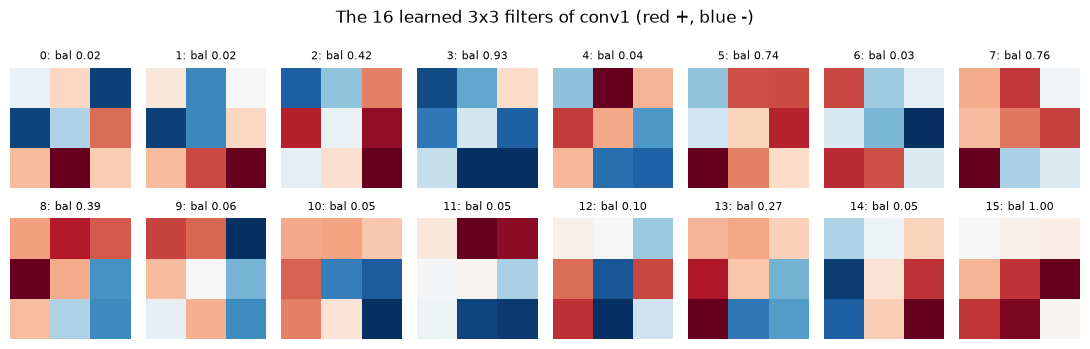

In [25]:
fig, axes = plt.subplots(2, 8, figsize=(11, 3.7))
bal = balance(learned)
for k, ax in enumerate(axes.flat):
    w = learned[k, 0]; m = w.abs().max()
    ax.imshow(w, cmap="RdBu_r", vmin=-m, vmax=m)
    ax.set_title(f"{k}: bal {bal[k]:.2f}", fontsize=8); ax.axis("off")
plt.suptitle("The 16 learned 3x3 filters of conv1 (red +, blue -)"); plt.tight_layout(); plt.show()

The low-balance filters contain both strong red and strong blue weights, often on opposite sides or corners of the grid, at various angles. That is the signature of an edge or contrast detector. They are rougher and less symmetric than the hand-designed filters of Section 5.2, which is typical of learned filters, but the network has arrived at the same kind of tool purely from the training signal. Filters 3 and 15, by contrast, are almost entirely one colour.

### 9.2 The feature maps

Filters are easier to understand by what they *produce*. Let's pass the ankle boot through the trained network and look at the feature maps after each convolution layer (after ReLU, which sets negative values to 0).

conv1 maps: (1, 16, 28, 28) | conv2 maps: (1, 32, 14, 14)
share of conv1 values that are zero: 0.38
share of conv2 values that are zero: 0.50


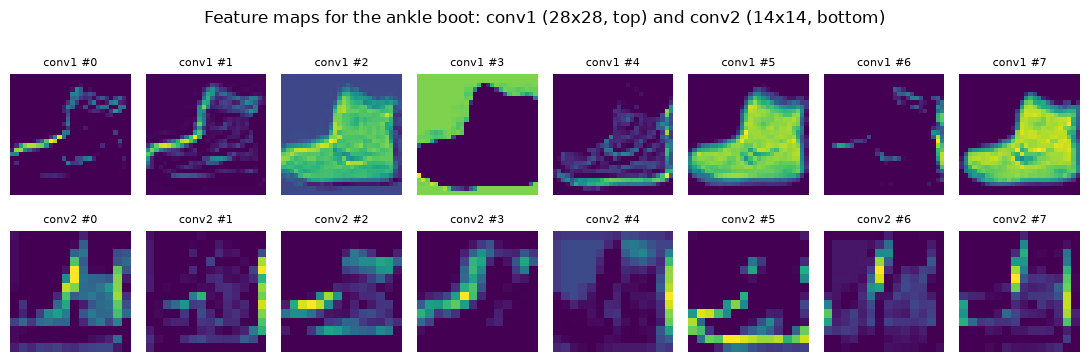

In [26]:
with torch.no_grad():
    a1 = cnn.features[:2](boot)          # after conv1 + ReLU: (1, 16, 28, 28)
    a2 = cnn.features[:5](boot)          # after conv2 + ReLU: (1, 32, 14, 14)
print("conv1 maps:", tuple(a1.shape), "| conv2 maps:", tuple(a2.shape))
print("share of conv1 values that are zero:", f"{(a1 == 0).float().mean().item():.2f}")
print("share of conv2 values that are zero:", f"{(a2 == 0).float().mean().item():.2f}")
fig, axes = plt.subplots(2, 8, figsize=(11, 3.9))
for k in range(8):
    axes[0, k].imshow(a1[0, k], cmap="viridis"); axes[0, k].set_title(f"conv1 #{k}", fontsize=8)
    axes[1, k].imshow(a2[0, k], cmap="viridis"); axes[1, k].set_title(f"conv2 #{k}", fontsize=8)
for ax in axes.flat: ax.axis("off")
plt.suptitle("Feature maps for the ankle boot: conv1 (28x28, top) and conv2 (14x14, bottom)")
plt.tight_layout(); plt.show()

The first-layer maps (top row, 28×28) are easy to read. Some light up along particular edges of the boot, such as the sole or the front. Others light up across the whole boot or, like map 3, across the background, which matches filter 3's same-sign weights. Each map is a different "view" of the same image.

The second-layer maps (bottom row, 14×14) are coarser and harder to interpret, which is normal: each value now combines 16 first-layer maps across an 8×8 window of the original image. They respond to combinations, such as a particular edge in a particular region.

The numbers back this up. In the first layer, 0.38 of the values are zero; in the second layer, 0.50 are. Deeper features are more **selective**: each one switches on for fewer locations, because it responds to a more specific combination of patterns.

> **Common mistake:** over-reading feature-map pictures. A map that "looks like" it detects heels may be responding to something else entirely, such as overall brightness in that region. Pictures are a starting point for questions, not proof; back them up with measurements, as we did with the balance score and the zero fractions.

> **Check yourself 8.** Filter 15 has a balance of 1.00. Would you expect its feature map for the boot to highlight edges, or something else? Why?

## Putting It All Together

Let's reassemble the picture from Section 1, now that you have seen every part.

An image enters as a tensor of shape `(N, C, H, W)`. An MLP would flatten it immediately, and we proved that this discards spatial structure: an MLP trained on shuffled pixels scored 0.8527, the same as on real images (0.8528, sign-test p = 1).

A CNN keeps the 2D layout. Its convolution layers slide small **learned filters** across the image, with the same weights at every position, producing **feature maps** that show where each pattern occurs. This weight sharing is enormously efficient: our first layer needed 160 parameters, against 9,847,040 for a fully connected layer with the same outputs. **Padding** controls whether the maps shrink, and **pooling** halves them, so that each layer's **receptive field** grows: 3, 4, 8 and then 10 pixels wide in our network. That growth lets later layers combine edges into parts. Finally, a small head flattens the last maps and classifies.

Trained on Fashion-MNIST, this CNN reached 0.8929 on validation and 0.8903 on the held-out test set. Its errors are concentrated in visually similar upper-body garments. Its first-layer filters became edge detectors without being told to (median balance 0.06, down from 0.30 at the start). And its built-in assumption that neighbours matter is real: the same CNN on shuffled pixels lost accuracy, falling from 0.8643 to 0.8341 after 2 epochs, with p = 1.14e-26.

> 🖼 *IMAGE 5.2.3 — What Each Part of a CNN Contributes.* A horizontal band divided into five labelled panels connected by arrows, white background. Panel 1 "Tensor (N, C, H, W)": a small stack of greyscale squares with the axes N, C, H, W marked. Panel 2 "Convolution": a 3×3 orange filter sliding over a grid with a curved arrow, beside it the words "local + shared weights". Panel 3 "Feature maps": three small maps showing a vertical edge, a horizontal edge and a filled silhouette of a boot, in red/blue. Panel 4 "Pooling": a 4×4 grid with coloured 2×2 blocks shrinking to a 2×2 grid, labelled "smaller maps, larger receptive field". Panel 5 "Head": a flatten bar into a small orange box, then a bar chart with "Ankle boot" tallest. Beneath panels 2–4 a bracket labelled "repeat: edges → parts → shapes". Takeaway: each component has one job, and together they turn pixels into a decision while respecting the image's 2D structure.

## Summary

- Images are stored as tensors of shape `(N, C, H, W)` in PyTorch: batch, channels, height, width. Plotting libraries usually want `(H, W, C)`, so use `permute` when switching.
- Flattening discards which pixels are neighbours. An MLP scored the same on shuffled and real pixels, proving it ignores spatial structure.
- A **convolution** slides a small filter over the input and computes a weighted sum at each position, producing a **feature map**. The same weights are reused everywhere (**weight sharing**), which makes convolution layers very parameter-efficient.
- **Padding**, **stride** and **pooling** control the size of feature maps; output size = ⌊(input + 2 × padding − kernel) / stride⌋ + 1.
- Stacking layers grows the **receptive field**, so later layers combine simple features into more complex ones: a **hierarchy** from edges to parts to objects.
- Our CNN reached 0.8903 on the test set, with most errors between similar garments such as shirts, T-shirts, pullovers and coats.
- Its learned filters became edge-like, and shuffling the pixels hurt it significantly. Its inductive bias helps when it is true and hurts when it is false.
- Choose settings such as the number of epochs on the validation set; use the test set once, at the end.

## Glossary

| Term | Meaning |
|---|---|
| CNN (convolutional neural network) | A network whose early layers are convolutions, designed for grid-like data such as images. |
| Tensor shape `(N, C, H, W)` | Batch size, channels, height, width: PyTorch's layout for image batches. |
| Channel | One kind of value per pixel; 1 for greyscale, 3 for colour (RGB). |
| Flatten | Reshape a multi-dimensional tensor into one long vector per example. |
| Spatial structure | The 2D arrangement of pixels: which pixels are neighbours. |
| Filter (kernel) | A small grid of learnable weights slid across the input. |
| Convolution | Sliding a filter across the input and computing a weighted sum at each position. |
| Feature map | The output grid of one filter, showing where its pattern appears. |
| Weight sharing | Using the same filter weights at every position in the input. |
| Inductive bias | An assumption about the problem built into a model's architecture. |
| Padding | Values (usually zeros) added around the input border. |
| Stride | How many positions the filter moves at each step. |
| Pooling (max / average) | Summarising small blocks of a feature map to shrink it. |
| Receptive field | The region of the input that can affect a given output value. |
| Hierarchical features | Features organised in levels, each built from the simpler level below. |
| Sign test | A test comparing two models using only the examples on which they disagree. |
| Balance (of a filter) | In this note: abs(sum of weights) / sum of absolute weights; near 0 means edge-like. |

## Answers to Check Yourself

**1.** `(16, 3, 224, 224)`: 16 images, 3 colour channels, 224 rows, 224 columns.

**2.** Using the same permutation keeps the task learnable and fair: a given pixel position still means the same thing in every image, just at a different place in the list. If each image were shuffled differently, the pixel values would carry no consistent positional meaning, and *no* model could learn much. That would not test whether the model uses spatial structure; it would just destroy the information.

**3.** The maps would stay at 32 channels × 14 × 14, so `Flatten` would produce 32 × 14 × 14 = 6,272 numbers per image. The first `nn.Linear` would then need `in_features=6272`, otherwise PyTorch raises a shape error.

**4.** All the weights are positive and equal, so it adds up the brightness in each 3×3 patch. Its feature map is a slightly blurred copy of the image. It is not a good edge detector: its weights do not cancel out (its balance is 1), so it responds to brightness, not to change.

**5.** ⌊(224 + 2 × 3 − 7) / 2⌋ + 1 = ⌊223 / 2⌋ + 1 = 111 + 1 = 112. The output is 112×112.

**6.** The head is fully connected: after flattening, every one of the 1,568 values (covering all 7×7 positions of all 32 maps) feeds into the head. Each value describes a different 10×10 region, and together those regions cover the whole image, so the head can combine evidence from every part of the garment.

**7.** Choosing the epoch is a decision based on data. If we made that decision using the test set, the test score would no longer be an honest estimate of performance on new data, because we would have picked the epoch that happened to suit those particular test images. The validation set exists to absorb those decisions; the test set is kept for one final, unbiased measurement.

**8.** Something else. With a balance of 1.00, its weights all share one sign, so on a uniform patch they do not cancel. It responds to overall brightness (if the weights are positive) or darkness (if they are negative) across each patch, so its map looks like a filled-in silhouette or its inverse, rather than a set of outlines.